# 01 · Data: CAMMESA monthly demand by region, 2017–2025

Two sources, same fields (month, agent, region, tariff category, MWh):

| Period | Source |
|---|---|
| Jan 2017 – Dec 2018 | *Demanda últimos años*, CAMMESA open data (datos.gob.ar) — the file used in the course |
| Jan 2019 – Dec 2025 | *Base de datos Informe Anual* 2020–2025, CAMMESA (each file covers its year and the previous one) |

Rows of the *Mercado a Término* category carry filler values in the source and are left out, as in the course.

In [1]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cammesa.plots import style, BLUE, ORANGE, AQUA, YELLOW, RULE, INK2, MUTED
style(); pd.set_option('display.precision', 1); pd.set_option('display.width', 160)
FIG = '../docs/figures/'

In [2]:
from cammesa.data import load_raw, regional_series, extended_regional_series
from cammesa.annual import read_all_annual
raw = load_raw()
tp = regional_series(raw)
annual = read_all_annual()
ext = extended_regional_series(raw)
print(f'Open-data file: {len(raw):,} rows, {tp.indice_tiempo.min()} to {tp.indice_tiempo.max()}')
print(f'Annual reports: {len(annual):,} rows, {annual.indice_tiempo.min()} to {annual.indice_tiempo.max()}')
print(f'Extended regional series: {len(ext)} rows = {ext.region.nunique()} regions x {ext.indice_tiempo.nunique()} months')

Open-data file: 40,388 rows, 2017-01 to 2020-02
Annual reports: 87,396 rows, 2019-01 to 2025-12
Extended regional series: 972 rows = 9 regions x 108 months


## Do the two sources agree?

They overlap from January 2019 to February 2020. The comparison is per region and month.

In [3]:
a = tp.set_index(['region', 'indice_tiempo'])['demanda_MWh']
b = regional_series(annual).set_index(['region', 'indice_tiempo'])['demanda_MWh']
j = pd.concat([a.rename('open data'), b.rename('annual reports')], axis=1, join='inner')
j['difference (%)'] = (j['annual reports'] / j['open data'] - 1) * 100
print(f"{len(j)} region-months; median |difference| {j['difference (%)'].abs().median():.3f} %")
j.reindex(j['difference (%)'].abs().sort_values(ascending=False).index).head(6)

126 region-months; median |difference| 0.000 %


open data  annual reports  difference (%)
region     indice_tiempo                                           
CUYO       2020-02          7.1e+05         6.8e+05            -5.1
NOROESTE   2020-02          8.9e+05         9.0e+05             1.8
LITORAL    2020-02          1.3e+06         1.4e+06             1.3
NOROESTE   2020-01          1.1e+06         1.1e+06             1.0
           2019-12          9.9e+05         9.9e+05             0.8
PATAGONICA 2020-01          4.9e+05         4.9e+05            -0.6

They match except in the last three months of the open-data file, which held provisional values that CAMMESA corrected later (up to 5 % in Cuyo, February 2020). The extended series therefore uses the annual reports from 2019 on. The course analyses (notebooks 02–05) keep the original file so their numbers stay as reported.

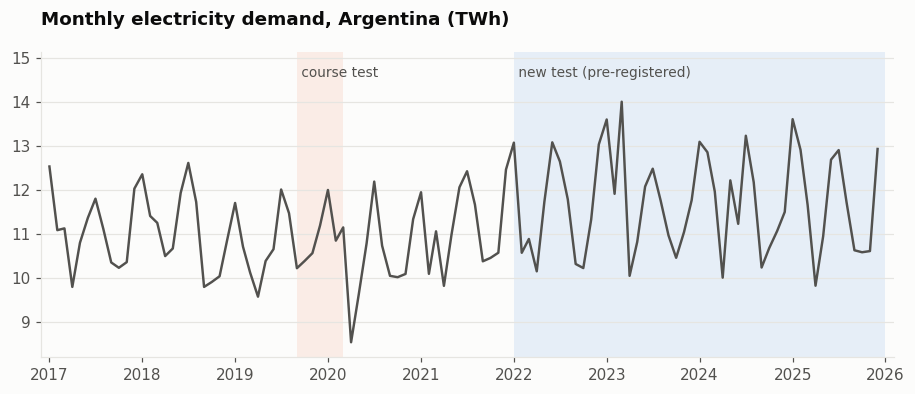

In [4]:
t = ext.groupby('indice_tiempo')['demanda_MWh'].sum() / 1e6
x = pd.PeriodIndex(t.index, freq='M').to_timestamp()
fig, ax = plt.subplots(figsize=(10, 3.6))
for (a0, b0, lab, col) in [('2019-09', '2020-02', 'course test', ORANGE), ('2022-01', '2025-12', 'new test (pre-registered)', BLUE)]:
    ax.axvspan(pd.Timestamp(a0), pd.Timestamp(b0) + pd.offsets.MonthEnd(0), color=col, alpha=0.10, lw=0)
    ax.text(pd.Timestamp(a0), t.max() * 1.035, ' ' + lab, color=INK2, fontsize=9, va='bottom')
ax.plot(x, t.values, color=INK2, lw=1.6)
ax.set_title('Monthly electricity demand, Argentina (TWh)', pad=18); ax.set_ylim(t.min() * 0.96, t.max() * 1.08); ax.margins(x=0.01)
fig.savefig(FIG + 'fig01_demand.png'); plt.show()

In [5]:
yearly = ext.groupby('anio')['demanda_MWh'].sum().div(1e6).rename('TWh').to_frame()
yearly['change (%)'] = yearly['TWh'].pct_change() * 100
yearly.T

anio,2017,2018,2019,2020,2021,2022,2023,2024,2025
TWh,132.5,133.0,128.9,127.3,133.9,138.8,140.9,140.2,141.0
change (%),NaN,0.4,-3.1,-1.3,5.2,3.7,1.5,-0.5,0.5


## External variables

Downloaded with `scripts/download_external.py` (needs internet; the CSVs are in `data/external/`):

- **Weather** — Open-Meteo daily temperature for 1–3 cities per region → monthly heating and cooling degree-days (base 18 °C).
- **Activity** — INDEC's monthly economic activity estimator (EMAE).
- **Tariff proxy** — regional CPI for *housing, water, electricity, gas and other fuels* divided by the general CPI: how much more expensive utilities got in real terms.

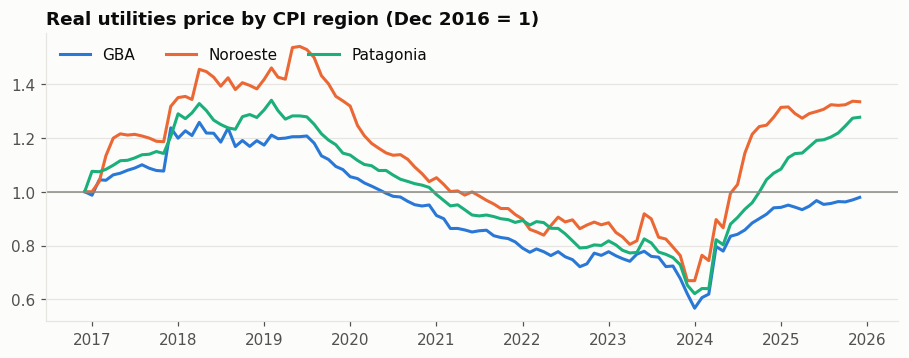

In [6]:
p = pd.read_csv('../data/external/prices_monthly_regions.csv', dtype={'indice_tiempo': str})
g = p.drop_duplicates(['cpi_region', 'indice_tiempo']).pivot(index='indice_tiempo', columns='cpi_region', values='relative_price')
g = g.loc[:'2025-12']
fig, ax = plt.subplots(figsize=(10, 3.4))
xs = pd.PeriodIndex(g.index, freq='M').to_timestamp()
for c, col in zip(['GBA', 'Noroeste', 'Patagonia'], [BLUE, ORANGE, AQUA]):
    ax.plot(xs, g[c], color=col, label=c)
ax.axhline(1, color=MUTED, lw=1)
ax.set_title('Real utilities price by CPI region (Dec 2016 = 1)'); ax.legend(ncol=3, loc='upper left')
fig.savefig(FIG + 'fig02_tariffs.png'); plt.show()